# Module project: upgrade the clothes classifier to a neural network

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-1-fashion-mlp.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-2-deep-networks/files/project-1-fashion-mlp.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/fashion-mlp` folder in the course files, to check your work.
- **Data**: Fashion-MNIST (Zalando Research). Source: [https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion](https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion) · about: [https://github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist) · licence: MIT. `data.py` downloads it the first time you run it and keeps it in `data/`: `t10k-images-idx3-ubyte.gz`, `t10k-labels-idx1-ubyte.gz`, `train-images-idx3-ubyte.gz`, `train-labels-idx1-ubyte.gz`, 29.4 MB.

In [ ]:
%pip install -q torch matplotlib

In part 1 you built a linear classifier for Fashion-MNIST, and saw where it failed: it couldn't tell a shirt from a
T-shirt. Section 6.1 explains why fixed features run out of power, and section 6.2 gives the cure: let the model
**learn its own features** with hidden layers.

In this project you test that claim properly. You'll write one function that builds a network of any width and depth,
train eight architectures under identical conditions, and find out what actually helps. It's the kind of controlled
experiment interviewers love to hear about. The notebook attached above builds and runs the whole project; the
reference code is in the course files under `projects/fashion-mlp`.

## What you'll build

```mermaid
flowchart LR
    A[data.py<br/>Fashion-MNIST,<br/>from part 1] --> B[model.py<br/>mlp hidden=...<br/>any width and depth]
    B --> C[train.py<br/>one network]
    C --> D[sweep.py<br/>8 architectures,<br/>same budget]
    D --> E[evaluate.py<br/>best vs linear,<br/>class by class]
```

## Set up the project

```bash
mkdir fashion-mlp && cd fashion-mlp
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

Copy `data.py` from your part 1 clothes classifier: reusing your own code is part of the job.

```text
fashion-mlp/
    .gitignore
    README.md
    data.py
    evaluate.py
    model.pt
    model.py
    requirements.txt
    sweep.py
    train.py
```

In [2]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [3]:
%%writefile .gitignore
data/
outputs/
__pycache__/
*.pt
.venv/

Writing .gitignore


In [4]:
%%writefile data.py
"""Fashion-MNIST: 70,000 grey 28x28 photos of clothes in 10 classes (Zalando Research)."""
from pathlib import Path
from urllib.request import urlopen
import gzip
import torch

URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]


def _read(name, offset):
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        path.write_bytes(urlopen(URL + name).read())
    raw = gzip.decompress(path.read_bytes())
    return torch.frombuffer(bytearray(raw[offset:]), dtype=torch.uint8)


def load(split):
    """split: 'train' (60,000 images) or 't10k' (10,000). Returns images as (N, 784) floats in [0, 1] and labels."""
    x = _read(f"{split}-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
    t = _read(f"{split}-labels-idx1-ubyte.gz", 8).long()
    return x, t


def load_splits():
    x, t = load("train")
    g = torch.Generator().manual_seed(0)
    order = torch.randperm(len(x), generator=g)
    val, train = order[:10000], order[10000:]
    return (x[train], t[train]), (x[val], t[val]), load("t10k")


if __name__ == "__main__":
    (xtr, ttr), (xva, tva), (xte, tte) = load_splits()
    print(f"train {len(xtr)}, validation {len(xva)}, test {len(xte)} images of {xtr.shape[1]} pixels")
    print("images per class in training:", torch.bincount(ttr).tolist())

Writing data.py


## Step 1: a network of any shape

A multilayer perceptron is a stack of layers, each one a linear map followed by a non-linear activation (section 6.2).
We use ReLU, `max(0, a)`, which is what most modern networks use. With `hidden=[]` the function builds exactly the
softmax regression of part 1, so the comparison is fair: same code, same training, only the architecture changes.

In [5]:
%%writefile model.py
"""A multilayer perceptron of any width and depth (Bishop, section 6.2)."""
from torch import nn


def mlp(hidden, D=784, K=10):
    """hidden=[] gives softmax regression; hidden=[256, 256] gives two hidden layers of 256 ReLU units."""
    layers, width = [], D
    for h in hidden:
        layers += [nn.Linear(width, h), nn.ReLU()]
        width = h
    layers.append(nn.Linear(width, K))
    return nn.Sequential(*layers)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

Writing model.py


## Step 2: train one network

Each epoch is one pass over the 50,000 training images in mini-batches of 128, with the Adam optimizer (you'll study
optimizers properly in the next module). `model.train()` and `model.eval()` don't matter yet, but they will once you add
dropout in chapter 9, so it's a good habit.

In [6]:
%%writefile train.py
"""Train one network and report its accuracy. Example: python train.py --hidden 256 256 --epochs 8"""
import argparse
import time
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from data import load_splits
from model import mlp, count_parameters


def accuracy(model, x, t):
    with torch.no_grad():
        return (model(x).argmax(1) == t).float().mean().item()


def train(hidden, epochs=8, seed=0, verbose=False):
    torch.manual_seed(seed)
    (xtr, ttr), (xva, tva), _ = load_splits()
    model = mlp(hidden)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(xtr, ttr), batch_size=128, shuffle=True)
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        for x, t in loader:
            loss = F.cross_entropy(model(x), t)
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        if verbose:
            print(f"epoch {epoch}: train accuracy {accuracy(model, xtr, ttr):.3f}, validation {accuracy(model, xva, tva):.3f}")
    return model, accuracy(model, xtr, ttr), accuracy(model, xva, tva), time.time() - start


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--hidden", type=int, nargs="*", default=[256])
    ap.add_argument("--epochs", type=int, default=8)
    args = ap.parse_args()
    model, _, _, _ = train(args.hidden, args.epochs, verbose=True)
    print(f"{count_parameters(model):,} parameters")
    torch.save({"hidden": args.hidden, "state": model.state_dict()}, "model.pt")

Writing train.py


In [7]:
!python train.py --hidden 256

epoch 1: train accuracy 0.845, validation 0.834


epoch 2: train accuracy 0.867, validation 0.854


epoch 3: train accuracy 0.876, validation 0.861


epoch 4: train accuracy 0.886, validation 0.869


epoch 5: train accuracy 0.889, validation 0.869


epoch 6: train accuracy 0.892, validation 0.872


epoch 7: train accuracy 0.904, validation 0.880


epoch 8: train accuracy 0.909, validation 0.882


203,530 parameters


One hidden layer of 256 units reaches 0.882 validation accuracy in 8 epochs, against 0.846 for the linear model.

## Step 3: a controlled experiment

Now the real question: **what helps, width or depth?** `sweep.py` trains eight architectures with the same seed, the same
optimizer and the same 8 epochs, and records parameters, training accuracy and validation accuracy.

In [8]:
%%writefile sweep.py
"""How wide, how deep? Train several architectures for the same 8 epochs and compare."""
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from train import train
from model import count_parameters

ARCHITECTURES = [[], [16], [64], [256], [1024], [256, 256], [256, 256, 256], [64, 64, 64, 64, 64, 64]]
rows = []
print(f"{'hidden layers':24s} {'parameters':>10s} {'train acc':>10s} {'val acc':>8s}")
for hidden in ARCHITECTURES:
    model, tr, va, _ = train(hidden)
    n = count_parameters(model)
    rows.append((hidden, n, tr, va))
    print(f"{str(hidden) if hidden else 'none (linear)':24s} {n:10,d} {tr:10.3f} {va:8.3f}")

Path("outputs").mkdir(exist_ok=True)
plt.figure(figsize=(6, 4))
for hidden, n, tr, va in rows:
    plt.scatter(n, va, color="C0" if len(hidden) <= 1 else "C3")
    plt.annotate(str(hidden) if hidden else "linear", (n, va), fontsize=7, xytext=(4, -3), textcoords="offset points")
plt.xscale("log"); plt.xlabel("parameters"); plt.ylabel("validation accuracy")
plt.title("blue: one hidden layer or none, red: deeper")
plt.tight_layout(); plt.savefig("outputs/sweep.png", dpi=120)
print("saved outputs/sweep.png")

Writing sweep.py


In [9]:
!python sweep.py

hidden layers            parameters  train acc  val acc


none (linear)                 7,850      0.862    0.846


[16]                         12,730      0.865    0.847


[64]                         50,890      0.883    0.864


[256]                       203,530      0.909    0.882


[1024]                      814,090      0.918    0.886


[256, 256]                  269,322      0.905    0.877


[256, 256, 256]             335,114      0.913    0.884


[64, 64, 64, 64, 64, 64]     71,690      0.888    0.865


saved outputs/sweep.png


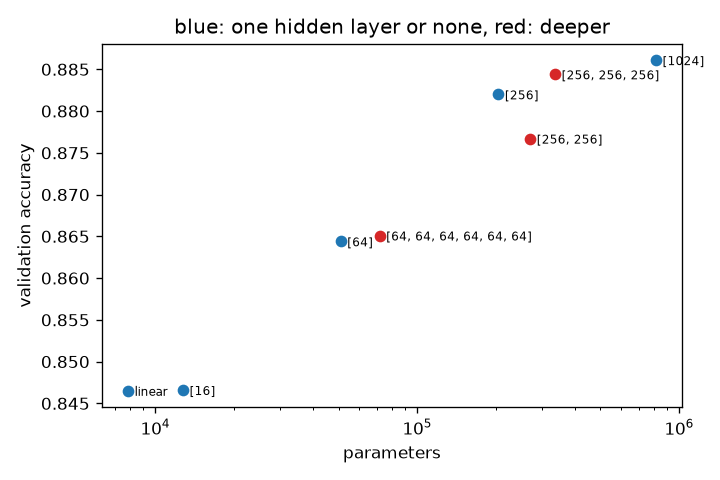

In [10]:
from IPython.display import Image
Image('outputs/sweep.png')

What the table says:

- **Any hidden layer helps**, but a tiny one (16 units) barely does: it squeezes 784 pixels through 16 numbers.
- **Width keeps helping**, with diminishing returns: 64 → 256 → 1024 units gives 0.864 → 0.882 → 0.886.
- **Depth isn't free.** Two or three layers of 256 do about as well as one. Six layers of 64 (0.865) do no better
  than a single layer of 64 (0.864): five extra layers bought nothing. The universal approximation results say one
  hidden layer is **enough in principle**; they don't say deeper is easier to train. Making
  deep networks train well is what chapters 7 and 9 are about (good initialization, normalization, residual
  connections).
- Training accuracy is above validation accuracy for the larger networks: the first signs of over-fitting, the topic of
  chapter 9.

Notice what this experiment does **not** tell you: with more epochs or a tuned learning rate, the ranking could change.
That's worth one honest sentence in your README.

## Step 4: test the winner, class by class

In [11]:
!python train.py --hidden 1024 --epochs 15

epoch 1: train accuracy 0.859, validation 0.844


epoch 2: train accuracy 0.880, validation 0.864


epoch 3: train accuracy 0.892, validation 0.875


epoch 4: train accuracy 0.902, validation 0.883


epoch 5: train accuracy 0.898, validation 0.875


epoch 6: train accuracy 0.910, validation 0.888


... (6 outputs left out)

epoch 13: train accuracy 0.933, validation 0.891


epoch 14: train accuracy 0.931, validation 0.890


epoch 15: train accuracy 0.932, validation 0.886


814,090 parameters


Validation accuracy peaks around epoch 13 and dips at 15 while training accuracy keeps rising: over-fitting again. We
keep the 15-epoch model anyway (choosing the best epoch is "early stopping", in chapter 9), and test it once, next to the
linear model:

In [12]:
%%writefile evaluate.py
"""Test the final network once, class by class, against the linear model (softmax regression)."""
import torch
from data import load_splits, CLASSES
from model import mlp
from train import train

_, _, (xte, tte) = load_splits()
saved = torch.load("model.pt")
net = mlp(saved["hidden"]); net.load_state_dict(saved["state"]); net.eval()
linear, _, _, _ = train([], epochs=15)


def per_class(model):
    with torch.no_grad():
        guess = model(xte).argmax(1)
    return torch.stack([(guess[tte == k] == k).float().mean() for k in range(10)]), (guess == tte).float().mean()


lin_k, lin_all = per_class(linear)
net_k, net_all = per_class(net)
print(f"{'class':12s} {'linear':>7s} {'MLP ' + str(saved['hidden']):>12s}")
for k in (net_k - lin_k).argsort(descending=True):
    print(f"{CLASSES[k]:12s} {lin_k[k]:7.3f} {net_k[k]:12.3f}")
print(f"{'ALL (test)':12s} {lin_all:7.3f} {net_all:12.3f}")

Writing evaluate.py


In [13]:
!python evaluate.py

class         linear   MLP [1024]
shirt          0.577        0.733
coat           0.744        0.873
dress          0.861        0.923
sneaker        0.932        0.967
sandal         0.922        0.950
bag            0.954        0.979
ankle boot     0.953        0.972
T-shirt        0.811        0.827
trouser        0.956        0.967
pullover       0.743        0.662
ALL (test)     0.845        0.885


Overall, 0.845 → 0.885. And the shirts, the linear model's worst class, jump from 0.58 to 0.73: the hidden layer has
learned features (collars, buttons, sleeve shapes) that no single pixel template can express. Coats improve a lot too.

But look at the bottom: **pullovers got worse**, 0.74 → 0.66. The network moved some pullovers into its new, better
"shirt" and "coat" regions. An overall improvement can hide a regression for one class, which in a real product might
be the one your users care about. Always look per class.

## Step 5: write the README and publish

In [14]:
%%writefile README.md
# Fashion-MNIST: how wide, how deep?

A study of multilayer perceptrons on Fashion-MNIST in PyTorch: eight architectures, from no hidden layer to six,
trained the same way and compared, then the best one tested against a linear model class by class.

![sweep](outputs/sweep.png)

## Results

| hidden layers | parameters | validation accuracy (8 epochs) |
|---|---|---|
| none (softmax regression) | 7,850 | 0.846 |
| [64] | 50,890 | 0.864 |
| [256] | 203,530 | 0.882 |
| [1024] | 814,090 | 0.886 |
| [256, 256, 256] | 335,114 | 0.884 |
| [64] x 6 | 71,690 | 0.865 |

Final model, one hidden layer of 1024 units, 15 epochs: **0.885 test accuracy** (linear: 0.845).
Shirts improved most (0.58 to 0.73), coats 0.74 to 0.87; pullovers got worse (0.74 to 0.66).

## Run it

```bash
pip install -r requirements.txt
python sweep.py                                  # compare 8 architectures
python train.py --hidden 1024 --epochs 15        # train the final model
python evaluate.py                               # test it, class by class
```

## What I learned

- A hidden layer learns its own features, which is what a linear model on pixels can't do.
- Width helped more than depth on this task; depth isn't free, and narrow deep networks trained worse.
- Overall accuracy can improve while one class gets worse: always look at per-class results.

Based on chapter 6 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Fashion-MNIST MLP: width vs depth study"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/fashion-mlp.git
git push -u origin main
```

## Make it yours

- **Repeat with 3 seeds.** Run the sweep with seeds 0, 1 and 2 and report the mean and spread. Which differences in
  the table are real, and which are noise?
- **Activations.** Swap ReLU for `nn.Tanh()` or `nn.Sigmoid()`. Which architectures suffer most, deep or wide?
- **Fix the pullovers.** Can you find a model or a training change that improves shirts without hurting pullovers?
- **Your own photos.** Photograph 10 pieces of your own clothing, convert them to 28 × 28 grey images with a dark
  background, and see what the model says. Why might it fail?

## On your CV

> **Fashion-MNIST architecture study** (PyTorch): controlled comparison of 8 MLP architectures (7.9k to 814k
> parameters); best model reached 88.5% test accuracy vs. 84.5% for softmax regression, improving the hardest class
> (shirts) from 58% to 73%. github.com/YOUR-USERNAME/fashion-mlp

## Check yourself

- [ ] All architectures were trained with the same seed, optimizer and number of epochs.
- [ ] You can explain why a hidden layer helps the shirts, in your own words.
- [ ] Your README mentions the class that got worse.